In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA

In [63]:
# Data Dummy

data = {
    'Date': pd.date_range(start='1/1/2019', periods=20, freq='D'),
    'Total Sales': np.round(np.random.uniform(10, 1000, 20), 2)
}

df = pd.DataFrame(data)
df.set_index('Date', inplace=True)
df.head()


,Total Sales
Date,
2019-01-01,358.85
2019-01-02,843.03
2019-01-03,476.57
2019-01-04,979.31
2019-01-05,637.80


In [64]:
Q1 = df['Total Sales'].quantile(0.25)
Q3 = df['Total Sales'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_clean = df[(df['Total Sales'] >= lower_bound) & (df['Total Sales'] <= upper_bound)]
df_clean


,Total Sales
Date,
2019-01-01,358.85
2019-01-02,843.03
2019-01-03,476.57
2019-01-04,979.31
2019-01-05,637.80
2019-01-06,135.00
2019-01-07,679.42
2019-01-08,331.85
2019-01-09,689.46


In [65]:
model = ARIMA(df_clean, order=(5, 1, 0))
model_fit = model.fit()
forecast = model_fit.forecast(steps=10)
forecast

c:\Users\agung\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\agung\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\agung\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


2019-01-21    631.994063
2019-01-22    442.856965
2019-01-23    346.940332
2019-01-24    292.887812
2019-01-25    390.520653
2019-01-26    570.050678
2019-01-27    306.619703
2019-01-28    357.232954
2019-01-29    359.864763
2019-01-30    458.690922
Freq: D, Name: predicted_mean, dtype: float64

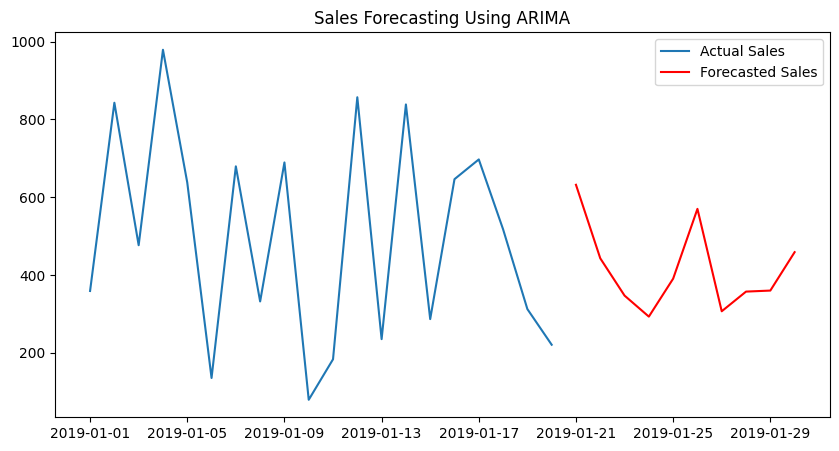

In [66]:
plt.figure(figsize=(10, 5))
plt.plot(df_clean, label='Actual Sales')
plt.plot(forecast, label='Forecasted Sales', color='red')
plt.legend(loc='best')
plt.title('Sales Forecasting Using ARIMA')
plt.show()


In [71]:
# Menghitung MAE, MSE, dan RMSE

from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

mae = mean_absolute_error(df_clean, model_fit.fittedvalues)
mse = mean_squared_error(df_clean, model_fit.fittedvalues)
mape = mean_absolute_percentage_error(df_clean, model_fit.fittedvalues)

print(f'MAE: {mae}')
print(f'MSE: {mse}')
print(f'MAPE: {mape}')

MAE: 197.08185319977036
MSE: 65114.40641302506
MAPE: 0.6278184806917846


In [81]:
data = {
    'Date': pd.date_range(start='1/1/2019', periods=20, freq='D'),
    'Total Sales': np.round(np.random.uniform(10, 1000, 20), 2)
}

df = pd.DataFrame(data)
df.set_index('Date', inplace=True)

Q1 = df['Total Sales'].quantile(0.25)
Q3 = df['Total Sales'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_clean = df[(df['Total Sales'] >= lower_bound) & (df['Total Sales'] <= upper_bound)]
df_clean

model = ARIMA(df_clean, order=(5, 1, 0))
model_fit = model.fit()
forecast = model_fit.forecast(steps=10)

mae = mean_absolute_error(df_clean, model_fit.fittedvalues)
mse = mean_squared_error(df_clean, model_fit.fittedvalues)
mape = mean_absolute_percentage_error(df_clean, model_fit.fittedvalues)

print(f'MAE: {mae}')
print(f'MSE: {mse}')
print(f'MAPE: {mape}')


MAE: 255.3756845987572
MSE: 95569.13807929108
MAPE: 2.3452904925646423


In [2]:
import pandas as pd
import numpy as np
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_percentage_error
import warnings
import itertools

warnings.filterwarnings('ignore')

# Menghasilkan data contoh
data = {
    'Date': pd.date_range(start='1/1/2019', periods=20, freq='D'),
    'Total Sales': np.round(np.random.uniform(10, 1000, 20), 2)
}

df = pd.DataFrame(data)
df.set_index('Date', inplace=True)

# Menghitung IQR untuk mendeteksi outlier
Q1 = df['Total Sales'].quantile(0.25)
Q3 = df['Total Sales'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Menghapus outlier
df_clean = df[(df['Total Sales'] >= lower_bound) & (df['Total Sales'] <= upper_bound)]

# Function to find the best ARIMA model parameters
def find_best_arima(df_clean, p_values, d_values, q_values, max_mape=0.50):
    best_score, best_order = float("inf"), None
    
    for p, d, q in itertools.product(p_values, d_values, q_values):
        try:
            model = ARIMA(df_clean, order=(p, d, q))
            model_fit = model.fit()
            # Menggunakan MAPE untuk memilih model terbaik
            mape = mean_absolute_percentage_error(df_clean['Total Sales'], model_fit.fittedvalues)
            if mape < best_score and mape < max_mape:
                best_score, best_order = mape, (p, d, q)
        except:
            continue
    return best_order, best_score

# Parameter ranges to try
p_values = range(0, 5)
d_values = range(0, 5)
q_values = range(0, 5)

# Find the best ARIMA parameters
best_order, best_score = find_best_arima(df_clean, p_values, d_values, q_values)

if best_order is not None:
    print(f'Best ARIMA order: {best_order} with MAPE: {best_score}')
    
    # Fit the best ARIMA model
    model = ARIMA(df_clean, order=best_order)
    model_fit = model.fit()
    
    # Membuat prediksi ke depan
    forecast = model_fit.forecast(steps=10)
    
    # Menghitung metrik evaluasi
    mae = mean_absolute_error(df_clean['Total Sales'], model_fit.fittedvalues)
    mse = mean_squared_error(df_clean['Total Sales'], model_fit.fittedvalues)
    mape = mean_absolute_percentage_error(df_clean['Total Sales'], model_fit.fittedvalues)
    
    # Menampilkan hasil
    print(f'MAPE: {mape}')
else:
    print('No ARIMA model met the MAPE criterion of less than 50%')


No ARIMA model met the MAPE criterion of less than 50%


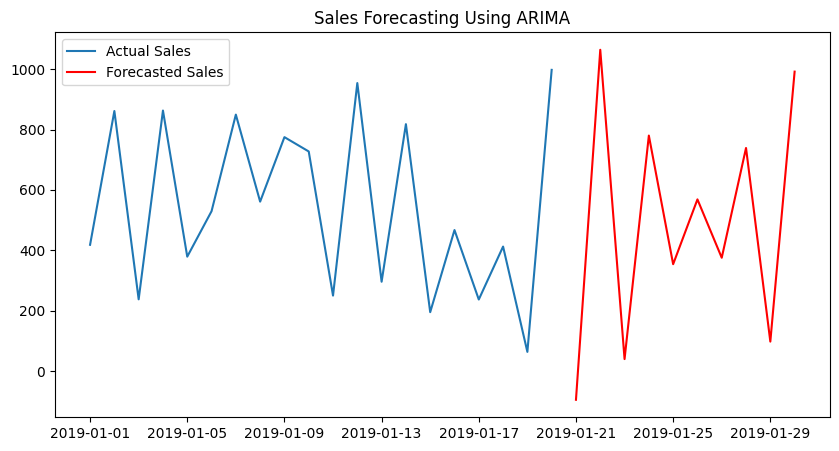

In [27]:
plt.figure(figsize=(10, 5))
plt.plot(df_clean, label='Actual Sales')
plt.plot(forecast, label='Forecasted Sales', color='red')
plt.legend(loc='best')
plt.title('Sales Forecasting Using ARIMA')
plt.show()

Simple moving average

In [2]:
import pandas as pd
import numpy as np

# Menghasilkan data contoh
data = {
    'Date': pd.date_range(start='1/1/2019', periods=20, freq='D'),
    'Total Sales': np.round(np.random.uniform(10, 1000, 20), 2)
}

df = pd.DataFrame(data)
df.set_index('Date', inplace=True)

# Menghitung IQR untuk mendeteksi outlier
Q1 = df['Total Sales'].quantile(0.25)
Q3 = df['Total Sales'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Menghapus outlier
df_clean = df[(df['Total Sales'] >= lower_bound) & (df['Total Sales'] <= upper_bound)]

# Menghitung Simple Moving Average (SMA)
df_clean['SMA'] = df_clean['Total Sales'].rolling(window=10).mean()

# Menampilkan hasil
df_clean


,Total Sales,SMA
Date,,
2019-01-01,339.71,NaN
2019-01-02,863.13,NaN
2019-01-03,683.56,NaN
2019-01-04,283.53,NaN
2019-01-05,87.72,NaN
2019-01-06,179.91,NaN
2019-01-07,778.10,NaN
2019-01-08,352.97,NaN
2019-01-09,754.03,NaN


EXPONENTIAL SMOOTHING

In [15]:
import pandas as pd
import numpy as np
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Menghasilkan data contoh
data = {
    'Date': pd.date_range(start='1/1/2019', periods=20, freq='D'),
    'Total Sales': np.round(np.random.uniform(10, 1000, 20), 2)
}

df = pd.DataFrame(data)
df.set_index('Date', inplace=True)

# Menghitung IQR untuk mendeteksi outlier
Q1 = df['Total Sales'].quantile(0.25)
Q3 = df['Total Sales'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Menghapus outlier
df_clean = df[(df['Total Sales'] >= lower_bound) & (df['Total Sales'] <= upper_bound)]

# Menggunakan Exponential Smoothing untuk peramalan
model = ExponentialSmoothing(df_clean['Total Sales'], trend='add', seasonal=None)
model_fit = model.fit(optimized=True)  # Menggunakan optimasi otomatis


# Melakukan prediksi ke depan
forecast_steps = 10
forecast = model_fit.forecast(steps=forecast_steps)

# Membuat DataFrame untuk prediksi
future_dates = pd.date_range(start=df_clean.index[-1] + pd.Timedelta(days=1), periods=forecast_steps, freq='D')
forecast_df = pd.DataFrame(forecast, index=future_dates, columns=['Predicted Sales'])

# Menggabungkan DataFrame asli dengan prediksi
df_combined = pd.concat([df_clean, forecast_df])

df_combined



c:\Users\agung\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


,Total Sales,Predicted Sales
2019-01-01,124.60,NaN
2019-01-02,473.93,NaN
2019-01-03,473.95,NaN
2019-01-04,719.01,NaN
2019-01-05,101.65,NaN
2019-01-06,139.19,NaN
2019-01-07,641.17,NaN
2019-01-08,681.14,NaN
2019-01-09,275.23,NaN
2019-01-10,156.49,NaN


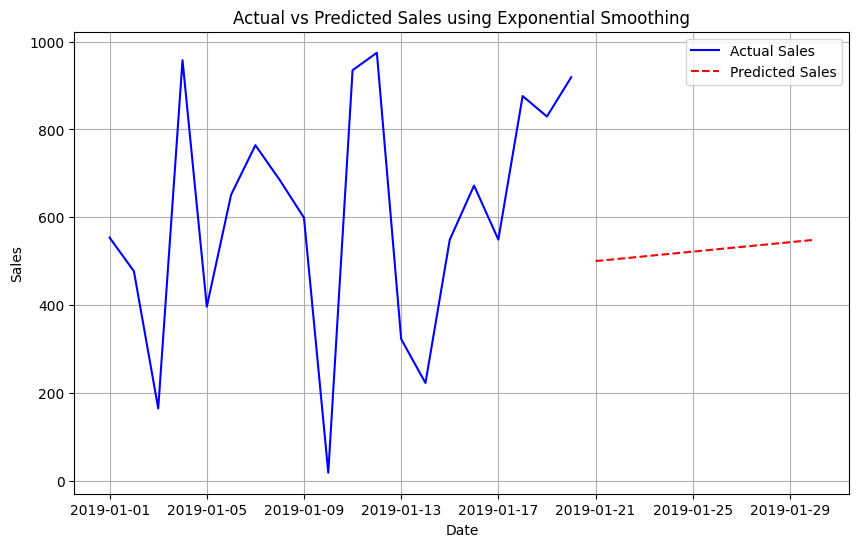

In [18]:
import matplotlib.pyplot as plt

# Membuat grafik garis
plt.figure(figsize=(10, 6))
plt.plot(df_clean.index, df_clean['Total Sales'], label='Actual Sales', color='blue')
plt.plot(forecast_df.index, forecast_df['Predicted Sales'], label='Predicted Sales', color='red', linestyle='--')
plt.title('Actual vs Predicted Sales using Exponential Smoothing')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.show()